# telco-ab-testing: walkthrough

**All data is synthetic** (seeded generator in `src/abtest/data.py`); it is not data from Airtel or any other operator.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
from IPython.display import Image, Markdown, display

In [2]:
from abtest.data import generate
generate().head()

,subscriber_id,region,tenure_months,group,pre_arpu,converted,post_arpu,opted_out,complaint
0,0,Central,36.2,treatment,195.42,0,180.12,0,0
1,1,Rift Valley,43.0,treatment,66.77,1,105.06,0,0
2,2,Central,8.2,treatment,61.23,0,0.00,0,0
3,3,Nyanza,12.3,treatment,81.80,0,78.14,0,0
4,4,Nairobi,2.9,control,706.14,0,620.94,0,0


## Run the full analysis pipeline

In [3]:
from abtest import run
_ = run.main()

# Decision memo: 'Bundle ya Wiki' USSD prompt (SYNTHETIC DATA)

**Decision: SHIP**

| Check | Result |
|---|---|
| Required n per group (8% base, +1pp MDE, 80% power) | 12,208 |
| Actual n (control / treatment) | 20,076 / 19,924 |
| SRM chi-square p | 0.447 (OK) |
| Conversion control → treatment | 8.09% → 9.04% |
| Absolute lift (95% CI) | +0.95pp (+0.40 to +1.50) |
| Relative lift | +11.7%, p = 0.00069 |
| ARPU lift, raw (95% CI) | KES +5.00 (+2.33 to +7.67) |
| ARPU lift, CUPED (95% CI) | KES +4.10 (+2.93 to +5.28) |
| CUPED variance reduction | 81% |
| Guardrail: USSD opt-out diff | +0.16pp, p = 0.10 |
| Guardrail: complaint diff | -0.10pp, p = 0.12 |
| A/A false-positive rate if peeking 10× | 18% (vs nominal 5%) |

**Why:** the primary metric is significant with a CI above zero, randomisation is healthy, and neither
guardrail moved. The test was analysed once at the pre-registered sample size, so the peeking
inflation shown above does not apply. Recommend a staged rollout (25% → 1

## Figures

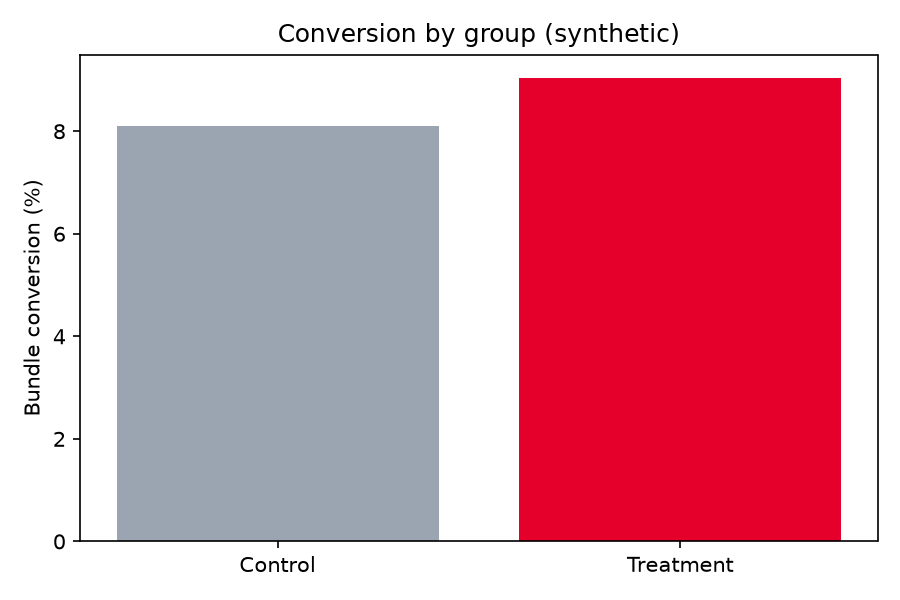

In [4]:
display(Image('../reports/figures/conversion.png'))

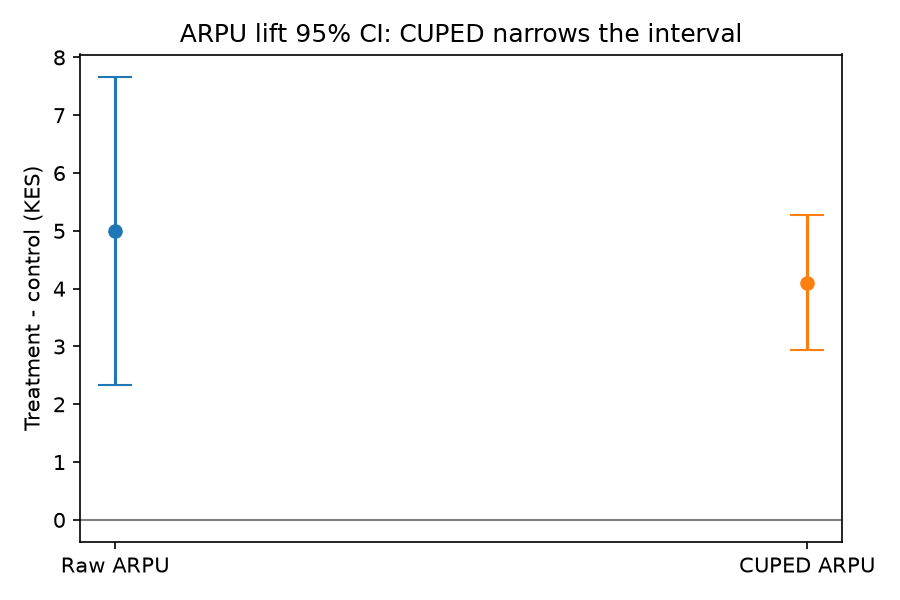

In [5]:
display(Image('../reports/figures/cuped_ci.png'))

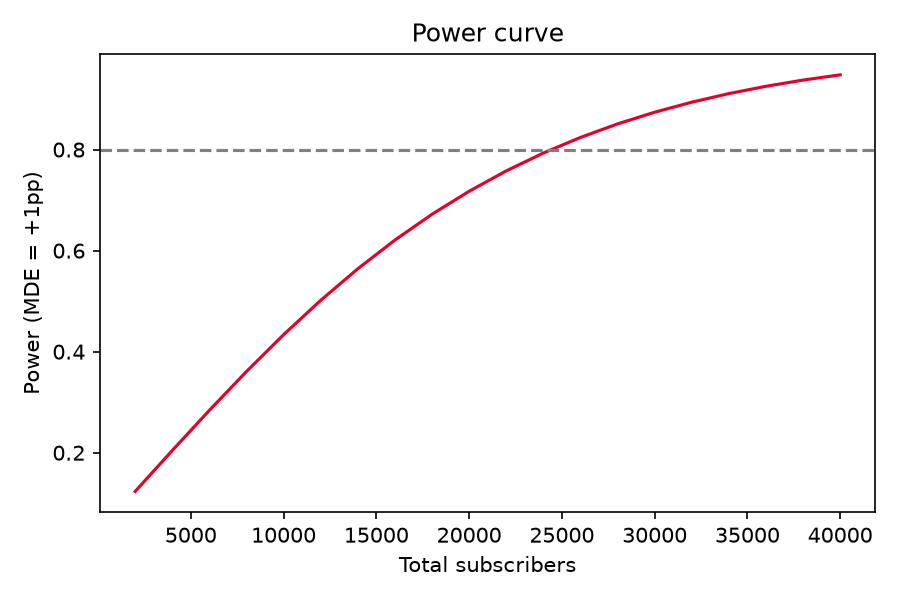

In [6]:
display(Image('../reports/figures/power_curve.png'))